# **Project :** Customer Segmentation Analysis

* Load Dataset and inspect structure : handle missing values and inconsistent data

* Descriptive statistics : average purchase frequency, customer lifetime value

* Feature selection : identify 2-3 key behavioural features for clustering (Recency, Frequency, Monetary - RFM analysis)

* Data Normalisation/Standardisation before clustering (use StandardScaler)

* Apply k-Means clustering - use the Elbow Method to determine optimal number of clusters (K)

* Visualise clusters using scatter plots (at least 2 feature combinations)

* Profile each cluster : calculate mean feature values per cluster and describe the customer type

* Bar Chart : Number of customers per cluster

* Insights section : What marketing action would you recommend for each segment ?

In [1]:
# Import Libararies

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import k_means


# Load Dataset and inspect structure : 

In [2]:
df = pd.read_csv("ecommerce_customer_data_custom_ratios.csv")
df.head()

,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


In [3]:
# Total Records & Columns
df.shape

(250000, 13)

* Total Records : 250000
* Total Columns : 13 

In [4]:
# Checking  Duplicate Values :
df.duplicated().sum()

np.int64(0)

In [5]:
# Dataframe Information : Columns, Cantaining Null or Not, Datatypes 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Customer ID            250000 non-null  int64  
 1   Purchase Date          250000 non-null  str    
 2   Product Category       250000 non-null  str    
 3   Product Price          250000 non-null  int64  
 4   Quantity               250000 non-null  int64  
 5   Total Purchase Amount  250000 non-null  int64  
 6   Payment Method         250000 non-null  str    
 7   Customer Age           250000 non-null  int64  
 8   Returns                202404 non-null  float64
 9   Customer Name          250000 non-null  str    
 10  Age                    250000 non-null  int64  
 11  Gender                 250000 non-null  str    
 12  Churn                  250000 non-null  int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 37.1 MB


# **Handle missing values and inconsistent data:**

In [6]:
# Checking Null Values in Dataset
df.isnull().sum()[df.isnull().sum()>0]

Returns    47596
dtype: int64

In [7]:
# Handling Null Values
df['Returns'] = df['Returns'].fillna(df['Returns'].mean())

In [8]:
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

# Descriptive statistics :
**Average purchase frequency, Customer lifetime value**

In [9]:
# Assumes each row represents one purchase
purchases_per_customer = df.groupby("Customer ID").size()
average_purchase_frequency = purchases_per_customer.mean()

print(f"Average purchases per customer: {average_purchase_frequency:.2f}")

Average purchases per customer: 5.03


In [10]:
# Historical customer value during the dataset's observed period
customer_lifetime_value = (
    df.groupby("Customer ID")["Total Purchase Amount"]
      .sum()
)

average_clv = customer_lifetime_value.mean()

print(f"Average customer lifetime value: {average_clv:.2f}")

Average customer lifetime value: 13716.56


In [11]:
# Dataframe Discriptive Analysis:
df.describe(include="number")

,Customer ID,Product Price,Quantity,Total Purchase Amount,Customer Age,Returns,Age,Churn
count,250000.00000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,25004.03624,254.659512,2.998896,2725.370732,43.940528,0.497861,43.940528,0.199496
std,14428.27959,141.568577,1.414694,1442.933565,15.350246,0.449890,15.350246,0.399622
min,1.00000,10.000000,1.000000,100.000000,18.000000,0.000000,18.000000,0.000000
25%,12497.75000,132.000000,2.000000,1477.000000,31.000000,0.000000,31.000000,0.000000
50%,25018.00000,255.000000,3.000000,2724.000000,44.000000,0.497861,44.000000,0.000000
75%,37506.00000,377.000000,4.000000,3974.000000,57.000000,1.000000,57.000000,0.000000
max,50000.00000,500.000000,5.000000,5350.000000,70.000000,1.000000,70.000000,1.000000


# Feature selection : 
 **identify 2-3 key behavioural features for clustering**
 
(Recency, Frequency, Monetary - RFM analysis)

In [12]:
# Convert Purchase Date to Datetime

df['Purchase Date'] = pd.to_datetime(df['Purchase Date'])

# Snapshot date = 1 day after the last purchase in the dataset
# (Recency is measured from this refrence date)
sanpshot_date = df['Purchase Date'].max() + pd.Timedelta(days=1)
print("Snapshot date:", sanpshot_date)

Snapshot date: 2023-09-16 12:24:08


In [14]:
# Build the RFM table (one row per customer)
rfm = df.groupby('Customer ID').agg(
    Recency   =  ('Purchase Date',          lambda x: (sanpshot_date - x.max()).days),
    Frequency =  ('Purchase Date',          'count'),
    Monetary  = ('Total Purchase Amount',   'sum') 
).reset_index()

print(rfm.shape)
rfm.head()

(49673, 4)


,Customer ID,Recency,Frequency,Monetary
0,1,58,1,3491
1,2,299,3,7988
2,3,89,8,22587
3,4,127,4,8715
4,5,171,8,12524


In [15]:
# Check the RFM features
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,49673.000000,49673.000000,49673.000000
mean,261.424979,5.032915,13716.559962
std,246.024001,2.206427,6840.208557
min,1.000000,1.000000,110.000000
25%,78.000000,3.000000,8719.000000
50%,185.000000,5.000000,13026.000000
75%,369.000000,6.000000,17966.000000
max,1353.000000,17.000000,55339.000000


In [16]:
# Check for missing values and duplicate customers
print(rfm.isnull().sum())
print("Duplicate customers:", rfm['Customer ID'].duplicated().sum())

Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64
Duplicate customers: 0


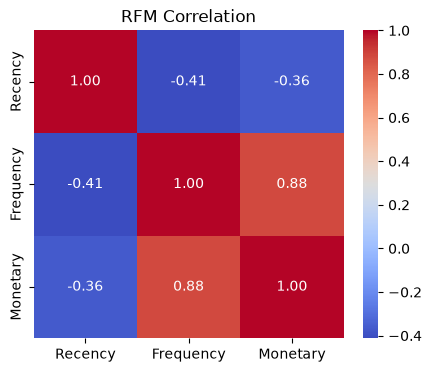

In [17]:
# Correlation between the features

plt.figure(figsize=(5, 4))
sns.heatmap(rfm[['Recency', 'Frequency', 'Monetary']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('RFM Correlation')
plt.show()

In [18]:
# Final feature selection for clustering

# Selected behavioural features for clustering
features = ['Recency', 'Frequency', 'Monetary']
X = rfm[features]
X.head()

,Recency,Frequency,Monetary
0,58,1,3491
1,299,3,7988
2,89,8,22587
3,127,4,8715
4,171,8,12524


# Explanation :
**Selected features (RFM):**

* **Recency** – days since the customer's last purchase (lower = more recently active)
* **Frequency** – total number of purchases made by the customer
* **Monetary** – total amount spent by the customer

These 3 features describe *how recently, how often and how much* a customer buys,
so they work well as behavioural inputs for k-Means clustering.

# Data Standardisation
**Data Normalisation/Standardisation before clustering (use StandardScaler)**

In [19]:
# Features are on very different scales (Monetary is in thousands, Recency in days)
X.describe().loc[['mean', 'std', 'min', 'max']]

,Recency,Frequency,Monetary
mean,261.424979,5.032915,13716.559962
std,246.024001,2.206427,6840.208557
min,1.000000,1.000000,110.000000
max,1353.000000,17.000000,55339.000000


In [20]:
scaler = StandardScaler()

# fit_transform learns the mean and std of each column, then standardises it
X_scaled = scaler.fit_transform(X)

# Convert back to a DataFrame so the columns keep their names
X_scaled = pd.DataFrame(X_scaled, columns=features, index=X.index)
X_scaled.head()

,Recency,Frequency,Monetary
0,-0.826858,-1.827822,-1.494934
1,0.152731,-0.921370,-0.837492
2,-0.700853,1.344760,1.296821
3,-0.546395,-0.468144,-0.731207
4,-0.367549,1.344760,-0.174347


In [21]:
print("Mean:\n",X_scaled.mean().round(4))
print("\nStd:\n", X_scaled.std().round(4))

Mean:
 Recency     -0.0
Frequency    0.0
Monetary    -0.0
dtype: float64

Std:
 Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


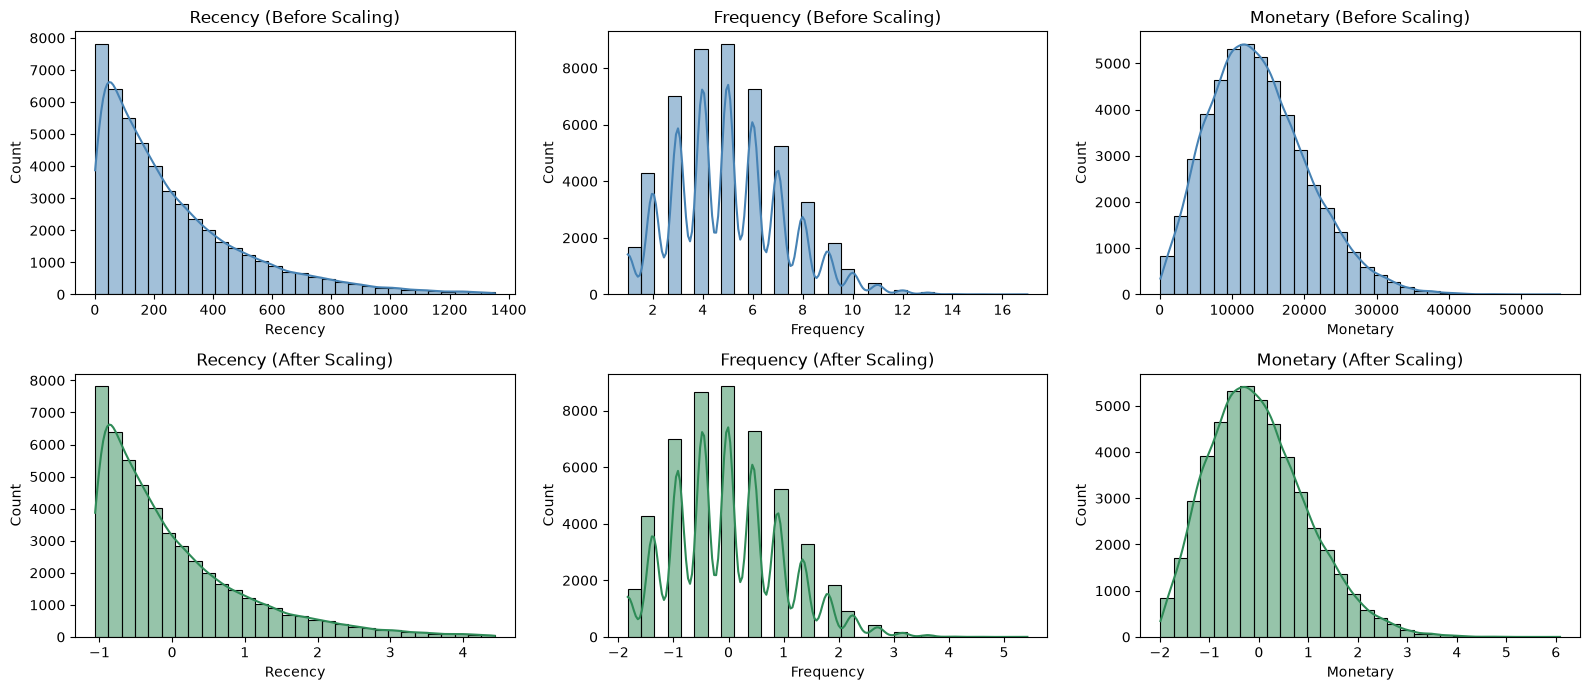

In [23]:
fig, axes = plt.subplots(2,3, figsize=(16, 7))

for i, col in enumerate(features):
    sns.histplot(X[col], bins=30, kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{col} (Before Scaling)')
    
    sns.histplot(X_scaled[col], bins=30, kde=True, ax=axes[1, i], color='seagreen')
    axes[1, i].set_title(f'{col} (After Scaling)')
    
plt.tight_layout()
plt.show()

**Observation: Before vs After Scaling**

* **Shape stays the same:** The distributions look identical before and after scaling.
  StandardScaler only changes the scale, not the pattern of the data.
* **Scale changes:** Before scaling, the features had very different ranges
  (Recency up to ~1400, Frequency up to ~17, Monetary up to ~50,000).
  After scaling, all three are centred around 0 and sit on a similar range.
* **Recency** is right-skewed: most customers purchased recently and only a few have been inactive for a long time.
* **Frequency** is made up of whole numbers, so it shows separate bars. Most customers buy 3 to 6 times.
* **Monetary** looks close to a bell curve, with a few high spenders on the right.

**Conclusion:** All three RFM features are now on the same scale (mean = 0, std = 1),
so no single feature will dominate k-Means clustering.